In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en días) se adjunta. Antes de hacer ningún cálculo numérico, conteste razonando sobre el grafo; después compruébelo.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT y, mirando sólo su forma, indique qué actividades parecen estar en la ruta más larga.  "
pregunta_2 = "2. Prediga, sin calcular tiempos, si el plazo del proyecto cambia en cada uno de estos casos: (a) H dura 2 días más; (b) E dura 2 días más; (c) F dura 2 días más. Anote su predicción.  "
pregunta_3 = "3. Calcule con Zaderenko los tiempos de los nodos, el calendario y las holguras.  "
pregunta_4 = "4. Compruebe las tres predicciones recalculando la duración. ¿Qué dato del calendario permitía acertar sin recalcular?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT y, mirando sólo su forma, indique qué actividades parecen estar en la ruta más larga.  

2. Prediga, sin calcular tiempos, si el plazo del proyecto cambia en cada uno de estos casos: (a) H dura 2 días más; (b) E dura 2 días más; (c) F dura 2 días más. Anote su predicción.  

3. Calcule con Zaderenko los tiempos de los nodos, el calendario y las holguras.  

4. Compruebe las tres predicciones recalculando la duración. ¿Qué dato del calendario permitía acertar sin recalcular?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 4       ),
    ('B'     , '---'      , 8       ),
    ('C'     , '---'      , 1       ),
    ('D'     , 'A,B,C'    , 3       ),
    ('E'     , 'C'        , 3       ),
    ('F'     , 'B,E'      , 6       ),
    ('G'     , 'D,E'      , 4       ),
    ('H'     , 'F,G'      , 3       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,4
B,---,8
C,---,1
D,"A,B,C",3
E,C,3
F,"B,E",6
G,"D,E",4
H,"F,G",3


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
    'H': 'Rodaje en plató',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores
H,Rodaje en plató


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT y, mirando sólo su forma, indique qué actividades parecen estar en la ruta más larga.  

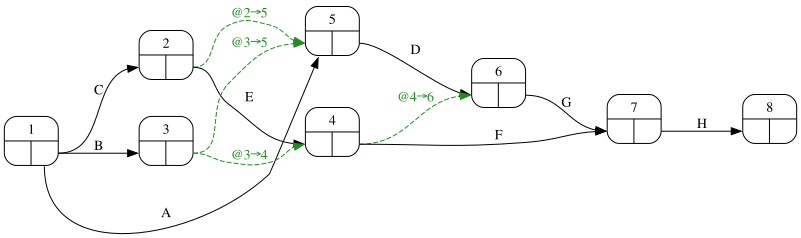

In [9]:
#| fig-cap: "Grafo PERT con numeración de nodos"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

A ojo sólo puede intuirse: las rutas con más actividades o con actividades largas son las candidatas. La forma del grafo no basta; hacen falta las duraciones.

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Prediga, sin calcular tiempos, si el plazo del proyecto cambia en cada uno de estos casos: (a) H dura 2 días más; (b) E dura 2 días más; (c) F dura 2 días más. Anote su predicción.  

Una predicción razonada: el plazo sólo cambia si la actividad está en la ruta más larga, o si el aumento supera la holgura total de la actividad. Sin cálculo sólo es seguro el primer caso si se ha identificado bien la ruta crítica; para los otros dos hace falta saber la holgura.

## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. Calcule con Zaderenko los tiempos de los nodos, el calendario y las holguras.  

Matriz de Zaderenko paso a paso. El primer paso muestra el resultado final; a partir del siguiente se construye desde el principio (avance con los botones):

In [12]:
#| tbl-cap: "Matriz de Zaderenko"
#| label: tbl-zaderenko
proyecto.display_zaderenko_pasos(datos_proyecto['duration'])

,1,2,3,4,5,6,7,8,early
1,,1.0,8.0,,4.0,,,,0.0
2,,,,3.0,0.0,,,,1.0
3,,,,0.0,0.0,,,,8.0
4,,,,,,0.0,6.0,,8.0
5,,,,,,3.0,,,8.0
6,,,,,,,4.0,,11.0
7,,,,,,,,3.0,15.0
8,,,,,,,,,18.0
late,0.0,6.0,8.0,9.0,8.0,11.0,15.0,18.0,


In [13]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])
calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio', 'H_total']]

,inicio_mas_temprano,fin_mas_temprano,inicio_mas_tardio,fin_mas_tardio,H_total
activity,,,,,
A,0,4,4,8,4
B,0,8,0,8,0
C,0,1,5,6,5
D,8,11,8,11,0
E,1,4,6,9,5
F,8,14,9,15,1
G,11,15,11,15,0
H,15,18,15,18,0


In [14]:
#| tbl-cap: "Fechas de cada actividad a partir de los tiempos de sus nodos"
#| label: tbl-fechasPaso
detalle_holguras(calendario, prelaciones)[['ES = máx EF pred.', 'EF = ES + d', 'LF = mín LS suc.', 'LS = LF − d', 'H_total = LS − ES']]

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d,H_total = LS − ES
actividad,,,,,
A,inicial → 0,0 + 4 = 4,mín(D: 8) = 8,8 − 4 = 4,4 − 0 = 4
B,inicial → 0,0 + 8 = 8,"mín(D: 8, F: 9) = 8",8 − 8 = 0,0 − 0 = 0
C,inicial → 0,0 + 1 = 1,"mín(D: 8, E: 6) = 6",6 − 1 = 5,5 − 0 = 5
D,"máx(A: 4, B: 8, C: 1) = 8",8 + 3 = 11,mín(G: 11) = 11,11 − 3 = 8,8 − 8 = 0
E,máx(C: 1) = 1,1 + 3 = 4,"mín(F: 9, G: 11) = 9",9 − 3 = 6,6 − 1 = 5
F,"máx(B: 8, E: 4) = 8",8 + 6 = 14,mín(H: 15) = 15,15 − 6 = 9,9 − 8 = 1
G,"máx(D: 11, E: 4) = 11",11 + 4 = 15,mín(H: 15) = 15,15 − 4 = 11,11 − 11 = 0
H,"máx(F: 14, G: 15) = 15",15 + 3 = 18,final → 18,18 − 3 = 15,15 − 15 = 0


## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. Compruebe las tres predicciones recalculando la duración. ¿Qué dato del calendario permitía acertar sin recalcular?  

In [16]:
casos = [('H', 2), ('E', 2), ('F', 2)]
filas = []
for act, extra in casos:
    d2 = datos_proyecto['duration'].copy(); d2[act] += extra
    nueva = proyecto.duration(d2)
    filas.append({'actividad': act, 'días de más': extra, 'holgura total': int(calendario.loc[act, 'H_total']),
                  'plazo antes': duracion_proyecto, 'plazo después': nueva,
                  'cambia': 'sí' if nueva > duracion_proyecto else 'no'})
pd.DataFrame(filas).set_index('actividad')

,días de más,holgura total,plazo antes,plazo después,cambia
actividad,,,,,
H,2,0,18,20,sí
E,2,5,18,18,no
F,2,1,18,19,sí


La regla es: el plazo cambia si y sólo si el retraso supera la holgura total de la actividad (para una actividad crítica la holgura es cero y cualquier retraso cuenta). El exceso sobre la holgura es exactamente lo que se alarga el proyecto.